# PBI 13 — Individual Business Analytics
**Isabelle Poh | ST1519 Agile MLOps | Group 2 — SP-buy fraud detection**

## 1. Business objectives
The Trust & Safety team needs actionable insights from historical orders and confirmed fraud labels. This notebook addresses three questions:

1. Which country and payment method combinations have elevated fraud rates or large fraud volumes?
2. How does time since the customer's first recorded order relate to fraud risk?
3. How do recorded fraudulent order values and associated refund amounts change over time within each market?

The analysis runs against the current AWS RDS MySQL data, rather than local historical CSVs. SQL performs aggregation in the database and Python validates results, produces charts and exports reports. The notebook reuses the analytics module so PBI 14 can automate the same logic.

## 2. Setup and database connection
Select the project's `.venv` kernel. The AWS Learner Lab must be active, and your current public IP must be allowed by the RDS security group. Database credentials remain in the local environment configuration; do not commit or print the `.env` file.

Resolve the project root explicitly so the same environment configuration works when the notebook starts inside `notebooks/`.

In [1]:
import os
import sys
from pathlib import Path
from time import perf_counter
import ast
import inspect
import textwrap

import pandas as pd
from IPython.display import display, Image

here = Path.cwd().resolve()
ROOT = next(
    (p for p in (here, *here.parents)
     if (p / "config.py").is_file()
     and (p / "src" / "analytics" / "isabelle_analytics.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open the notebook from the AMLOP_CA1_Group2 project.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analytics.isabelle_analytics import (
    analytics_connection, execute_query, get_analysis_period,
    query_fraud_by_payment, query_fraud_by_tenure,
    query_monthly_financial_exposure, validate_payment_results,
    validate_financial_results, plot_payment_heatmap,
    plot_tenure_fraud, plot_financial_exposure,
)

OUTPUT_DIR = ROOT / "reports" / "isabelle_analytics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MIN_LABELLED = 1000
pd.set_option("display.max_columns", None)


def show_sql(function):
    """Display the actual SQL from the reusable function, without executing it."""
    tree = ast.parse(textwrap.dedent(inspect.getsource(function)))
    for node in ast.walk(tree):
        if isinstance(node, ast.Assign) and any(
            isinstance(target, ast.Name) and target.id == "sql"
            for target in node.targets
        ):
            print(textwrap.dedent(ast.literal_eval(node.value)).strip())
            return
    raise ValueError(f"SQL assignment not found in {function.__name__}")

print("Project root located. Analytics functions imported.")

Project root located. Analytics functions imported.


## 3. Data relationships and analytical definitions
- `orders` joins to `labels` on `(country_code, order_id)`.
- `labels` joins to `customers` on `(country_code, customer_id)` when customer tenure is needed.
- A left join retains orders without valid labels. Only labels 0 and 1 are included in the fraud-rate denominator.
- Orders with missing order dates are excluded from the analysis period and the three queries.
- Fraud rate = fraudulent orders / valid labelled orders × 100. A zero denominator produces a missing rate rather than zero.
- Customer tenure is measured in calendar days from the first recorded order date, not account registration. Missing or negative tenure is classified as Unknown.
- Monetary values are reported separately by country in recorded dataset units; their currency denomination has not been confirmed. Refunds are not necessarily actual losses.

### Additional refund diagnostic SQL
This supplementary data quality check explains the flat refund series in Query 3. It is not counted as a fourth business question.

In [2]:
REFUND_DIAGNOSTIC_SQL = """
SELECT
    CASE WHEN l.is_fraud = 1 THEN 'Fraud'
         WHEN l.is_fraud = 0 THEN 'Non-fraud'
         ELSE 'Unlabelled' END AS fraud_status,
    COUNT(*) AS total_orders,
    SUM(CASE WHEN o.refund_value = 0 THEN 1 ELSE 0 END) AS zero_refunds,
    SUM(CASE WHEN o.refund_value > 0 THEN 1 ELSE 0 END) AS positive_refunds,
    SUM(CASE WHEN o.refund_value < 0 THEN 1 ELSE 0 END) AS negative_refunds,
    SUM(CASE WHEN o.refund_value IS NULL THEN 1 ELSE 0 END) AS missing_refunds,
    SUM(CASE WHEN o.refund_value > o.order_value THEN 1 ELSE 0 END) AS refund_exceeds_order
FROM orders AS o
LEFT JOIN labels AS l
    ON o.country_code = l.country_code AND o.order_id = l.order_id
WHERE o.order_date IS NOT NULL
GROUP BY fraud_status
"""

## 4. Retrieve and validate a consistent database snapshot
All three queries and the supplementary diagnostic run in one read-only transaction using the shared analytics connection. The connection must use TLS; the cipher check verifies encryption on this session. Aggregate counts are reconciled across the three queries and the diagnostic. This reduces the risk of inconsistent reports when another process is inserting new batches.

In [3]:
started = perf_counter()
query_times = {}
with analytics_connection() as conn:
    with conn.cursor() as cursor:
        cursor.execute("SHOW STATUS LIKE 'Ssl_cipher'")
        tls = cursor.fetchone()
        if not tls or not tls["Value"]:
            raise RuntimeError("RDS connection is not using TLS.")
    print("PASS: TLS connection verified.")
    period = get_analysis_period(conn)
    start_date = period.iloc[0]["start_date"]
    end_date = period.iloc[0]["end_date"]
    expected_orders = int(period.iloc[0]["total_orders"])

    t = perf_counter()
    q1 = query_fraud_by_payment(conn)
    validate_payment_results(q1, expected_orders)
    query_times["Query 1"] = perf_counter() - t

    t = perf_counter()
    q2 = query_fraud_by_tenure(conn)
    validate_payment_results(q2, expected_orders)
    query_times["Query 2"] = perf_counter() - t

    t = perf_counter()
    q3 = query_monthly_financial_exposure(conn)
    validate_financial_results(q3, expected_orders)
    query_times["Query 3"] = perf_counter() - t

    count_columns = ["total_orders", "labelled_orders", "fraud_orders",
                     "non_fraud_orders", "unlabelled_orders"]
    for col in count_columns:
        assert q1[col].sum() == q2[col].sum() == q3[col].sum(), col
    print("PASS: All three query totals match.")

    t = perf_counter()
    refund_audit = execute_query(conn, REFUND_DIAGNOSTIC_SQL)
    query_times["Refund diagnostic"] = perf_counter() - t

for col in refund_audit.columns.drop("fraud_status"):
    refund_audit[col] = pd.to_numeric(refund_audit[col])
assert refund_audit["total_orders"].sum() == expected_orders
assert (refund_audit[["zero_refunds", "positive_refunds", "negative_refunds", "missing_refunds"]]
        .sum(axis=1) == refund_audit["total_orders"]).all()
by_status = refund_audit.set_index("fraud_status")["total_orders"]
for status, col in [("Fraud", "fraud_orders"), ("Non-fraud", "non_fraud_orders"),
                    ("Unlabelled", "unlabelled_orders")]:
    assert by_status.get(status, 0) == q1[col].sum(), status
print("PASS: Refund diagnostic reconciled to the three business queries.")
print(f"Snapshot retrieval and validation: {perf_counter() - started:.2f}s")

display(period)
summary = pd.DataFrame({"metric": count_columns, "count": [int(q1[c].sum()) for c in count_columns]})
display(summary)
labelled = q1["labelled_orders"].sum()
print(f"Overall fraud rate: {100*q1['fraud_orders'].sum()/labelled:.2f}%" if labelled else "No valid labels.")

PASS: TLS connection verified.
PASS: Fraud rate calculations validated.
PASS: Order counts validated.
PASS: Unlabelled orders handled correctly.
PASS: Fraud rate calculations validated.
PASS: Order counts validated.
PASS: Unlabelled orders handled correctly.
PASS: Fraud rate calculations validated.
PASS: Order counts validated.
PASS: Unlabelled orders handled correctly.
PASS: Financial values validated.
PASS: Average fraudulent order values validated.
PASS: Financial anomaly counts validated.
PASS: All three query totals match.
PASS: Refund diagnostic reconciled to the three business queries.
Snapshot retrieval and validation: 40.22s


,start_date,end_date,total_orders
0,2022-11-12,2023-05-11,949889


,metric,count
0,total_orders,949889
1,labelled_orders,949874
2,fraud_orders,104422
3,non_fraud_orders,845452
4,unlabelled_orders,15


Overall fraud rate: 10.99%


## 5. Query 1 — Fraud risk by country and payment method
**Business question:** Which country-payment combinations should be prioritised for investigation?

The query reports total, labelled, fraudulent, non-fraudulent and unlabelled orders and the corresponding fraud rate. Rates and fraud counts are both important: a high rate on a small sample does not necessarily represent a high operational burden. The heatmap highlights groups with at least 1,000 valid labelled orders, an exploratory screening threshold rather than a significance test.

In [4]:
show_sql(query_fraud_by_payment)

SELECT
    o.country_code,
    o.payment_method,

    COUNT(*) AS total_orders,

    SUM(
        CASE
            WHEN l.is_fraud IN (0, 1) THEN 1
            ELSE 0
        END
    ) AS labelled_orders,

    SUM(
        CASE
            WHEN l.is_fraud = 1 THEN 1
            ELSE 0
        END
    ) AS fraud_orders,

    SUM(
        CASE
            WHEN l.is_fraud = 0 THEN 1
            ELSE 0
        END
    ) AS non_fraud_orders,

    SUM(
        CASE
            WHEN l.is_fraud IS NULL
                 OR l.is_fraud NOT IN (0, 1)
            THEN 1
            ELSE 0
        END
    ) AS unlabelled_orders,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN l.is_fraud = 1 THEN 1
                ELSE 0
            END
        )
        /
        NULLIF(
            SUM(
                CASE
                    WHEN l.is_fraud IN (0, 1) THEN 1
                    ELSE 0
                END
            ),
            0
        ),
        4
    ) AS frau

,country_code,payment_method,total_orders,labelled_orders,fraud_orders,non_fraud_orders,unlabelled_orders,fraud_rate_pct
0,BD,no payment,2,2.0,2.0,0.0,0.0,100.0000
1,PK,no payment,240,240.0,137.0,103.0,0.0,57.0833
2,BD,invoice,4,4.0,2.0,2.0,0.0,50.0000
3,PK,jazzcash wallet,2509,2509.0,1227.0,1282.0,0.0,48.9040
4,PK,invoice,414,414.0,187.0,227.0,0.0,45.1691
5,TH,no payment,82,82.0,32.0,50.0,0.0,39.0244
6,BD,payment on delivery,31352,31351.0,10178.0,21173.0,1.0,32.4647
7,PK,balance,9383,9383.0,2717.0,6666.0,0.0,28.9566
8,BD,balance,465,465.0,127.0,338.0,0.0,27.3118
9,PK,payment on delivery,93091,93090.0,24886.0,68204.0,1.0,26.7333


Highest fraud rates among sufficiently large groups:


,country_code,payment_method,total_orders,labelled_orders,fraud_orders,non_fraud_orders,unlabelled_orders,fraud_rate_pct
3,PK,jazzcash wallet,2509,2509.0,1227.0,1282.0,0.0,48.9040
6,BD,payment on delivery,31352,31351.0,10178.0,21173.0,1.0,32.4647
7,PK,balance,9383,9383.0,2717.0,6666.0,0.0,28.9566
9,PK,payment on delivery,93091,93090.0,24886.0,68204.0,1.0,26.7333
10,BD,antfinancial bkash,17889,17888.0,4647.0,13241.0,1.0,25.9783
11,BD,credit card,9807,9807.0,2467.0,7340.0,0.0,25.1555
13,PK,generic creditcard,65626,65625.0,13497.0,52128.0,1.0,20.5669
14,PK,credit card,13559,13559.0,2667.0,10892.0,0.0,19.6696
19,TH,generic creditcard,3637,3637.0,401.0,3236.0,0.0,11.0256
21,PH,payment on delivery,100613,100612.0,10741.0,89871.0,1.0,10.6757


Largest fraud volumes (all groups):


,country_code,payment_method,total_orders,labelled_orders,fraud_orders,non_fraud_orders,unlabelled_orders,fraud_rate_pct
9,PK,payment on delivery,93091,93090.0,24886.0,68204.0,1.0,26.7333
13,PK,generic creditcard,65626,65625.0,13497.0,52128.0,1.0,20.5669
21,PH,payment on delivery,100613,100612.0,10741.0,89871.0,1.0,10.6757
6,BD,payment on delivery,31352,31351.0,10178.0,21173.0,1.0,32.4647
22,PH,antfinancial gcash,102657,102655.0,8729.0,93926.0,2.0,8.5032
38,MY,online banking,124983,124980.0,4991.0,119989.0,3.0,3.9934
10,BD,antfinancial bkash,17889,17888.0,4647.0,13241.0,1.0,25.9783
40,MY,cybersource,110598,110598.0,3174.0,107424.0,0.0,2.8699
34,MY,payment on delivery,62325,62325.0,2942.0,59383.0,0.0,4.7204
32,PH,credit card,59239,59238.0,2864.0,56374.0,1.0,4.8347


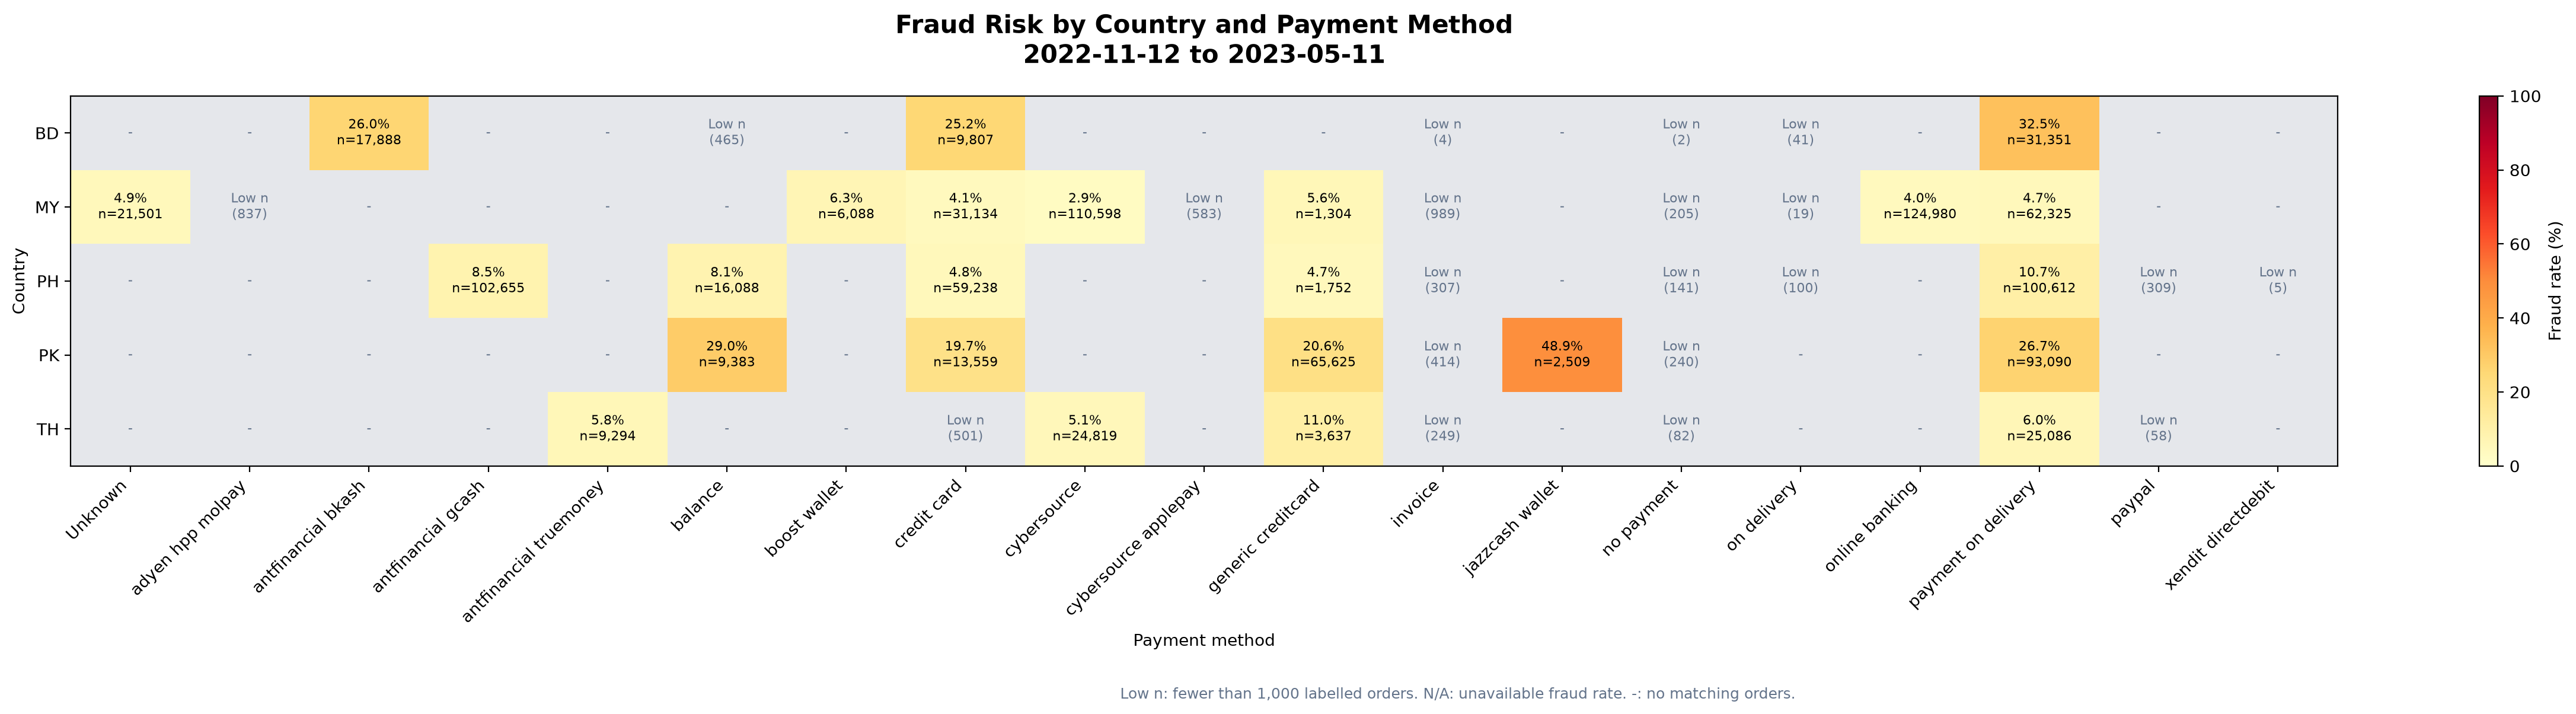

In [5]:
display(q1)
qualified = q1[q1["labelled_orders"] >= MIN_LABELLED]
print("Highest fraud rates among sufficiently large groups:")
display(qualified.sort_values("fraud_rate_pct", ascending=False).head(10))
print("Largest fraud volumes (all groups):")
display(q1.sort_values("fraud_orders", ascending=False).head(10))
q1.to_csv(OUTPUT_DIR / "q1_payment_fraud.csv", index=False)
q1_chart = plot_payment_heatmap(q1, start_date, end_date, OUTPUT_DIR,
                                min_labelled_orders=MIN_LABELLED)
display(Image(filename=str(q1_chart), width=1200))

### 5.1 Historical findings and recommended action
The original RDS results on 27 November 2026 covered orders dated 12 November 2022 to 11 May 2023. There were 949,889 orders, 949,874 valid labelled orders, 104,422 fraudulent orders and 15 unlabelled orders (overall labelled fraud rate: 10.99%).

- Pakistan's JazzCash Wallet had a 48.90% fraud rate among 2,509 labelled orders, making it the highest-rate group with at least 1,000 labels in that snapshot.
- Pakistan's payment on delivery had 24,886 fraudulent orders and a 26.73% fraud rate, representing a much larger investigation volume.
- Bangladesh's payment on delivery recorded a 32.46% fraud rate, compared with approximately 4.7% in Malaysia. Risk patterns differ across markets.
- Bangladesh's no-payment group recorded 100% fraud but only two labelled orders. This is too small a sample for a strong operational conclusion.

**Recommendation:** Investigate high-rate payment combinations and prioritise high-volume groups according to available review capacity. Avoid automatically blocking payments solely because of a country or payment method. These associations may reflect transaction mix or other confounding factors.

The values above describe the original snapshot; the live tables and charts will refresh if the database changes.

## 6. Query 2 — Customer tenure and fraud risk
**Business question:** Does the fraud rate differ according to how long a customer has been purchasing?

The query uses `DATEDIFF(order_date, first_order_datetime)` to construct six ordered tenure categories and an Unknown category. The Unknown group retains orders with missing customer records, missing first-order dates or negative tenure. All valid labelled orders are included in the overall reference rate.

In [6]:
show_sql(query_fraud_by_tenure)

WITH order_tenure AS (
    SELECT
        o.country_code,
        o.order_id,
        l.is_fraud,

        DATEDIFF(
            o.order_date,
            c.first_order_datetime
        ) AS tenure_days

    FROM orders AS o

    LEFT JOIN labels AS l
        ON o.country_code = l.country_code
        AND o.order_id = l.order_id

    LEFT JOIN customers AS c
        ON l.country_code = c.country_code
        AND l.customer_id = c.customer_id

    WHERE o.order_date IS NOT NULL
),

tenure_groups AS (
    SELECT
        *,
        CASE
            WHEN tenure_days IS NULL
                 OR tenure_days < 0
                THEN 'Unknown'

            WHEN tenure_days = 0
                THEN '0 days'

            WHEN tenure_days <= 7
                THEN '1-7 days'

            WHEN tenure_days <= 30
                THEN '8-30 days'

            WHEN tenure_days <= 90
                THEN '31-90 days'

            WHEN tenure_days <= 180
                THEN '91-180 days'

            E

,tenure_group,total_orders,labelled_orders,fraud_orders,non_fraud_orders,unlabelled_orders,fraud_rate_pct
0,0 days,14274,14274.0,6763.0,7511.0,0.0,47.3799
1,1-7 days,11728,11728.0,4668.0,7060.0,0.0,39.8022
2,8-30 days,17496,17496.0,6575.0,10921.0,0.0,37.5800
3,31-90 days,34442,34442.0,8102.0,26340.0,0.0,23.5236
4,91-180 days,43107,43107.0,6332.0,36775.0,0.0,14.6890
5,181+ days,827949,827949.0,71786.0,756163.0,0.0,8.6703
6,Unknown,893,878.0,196.0,682.0,15.0,22.3235


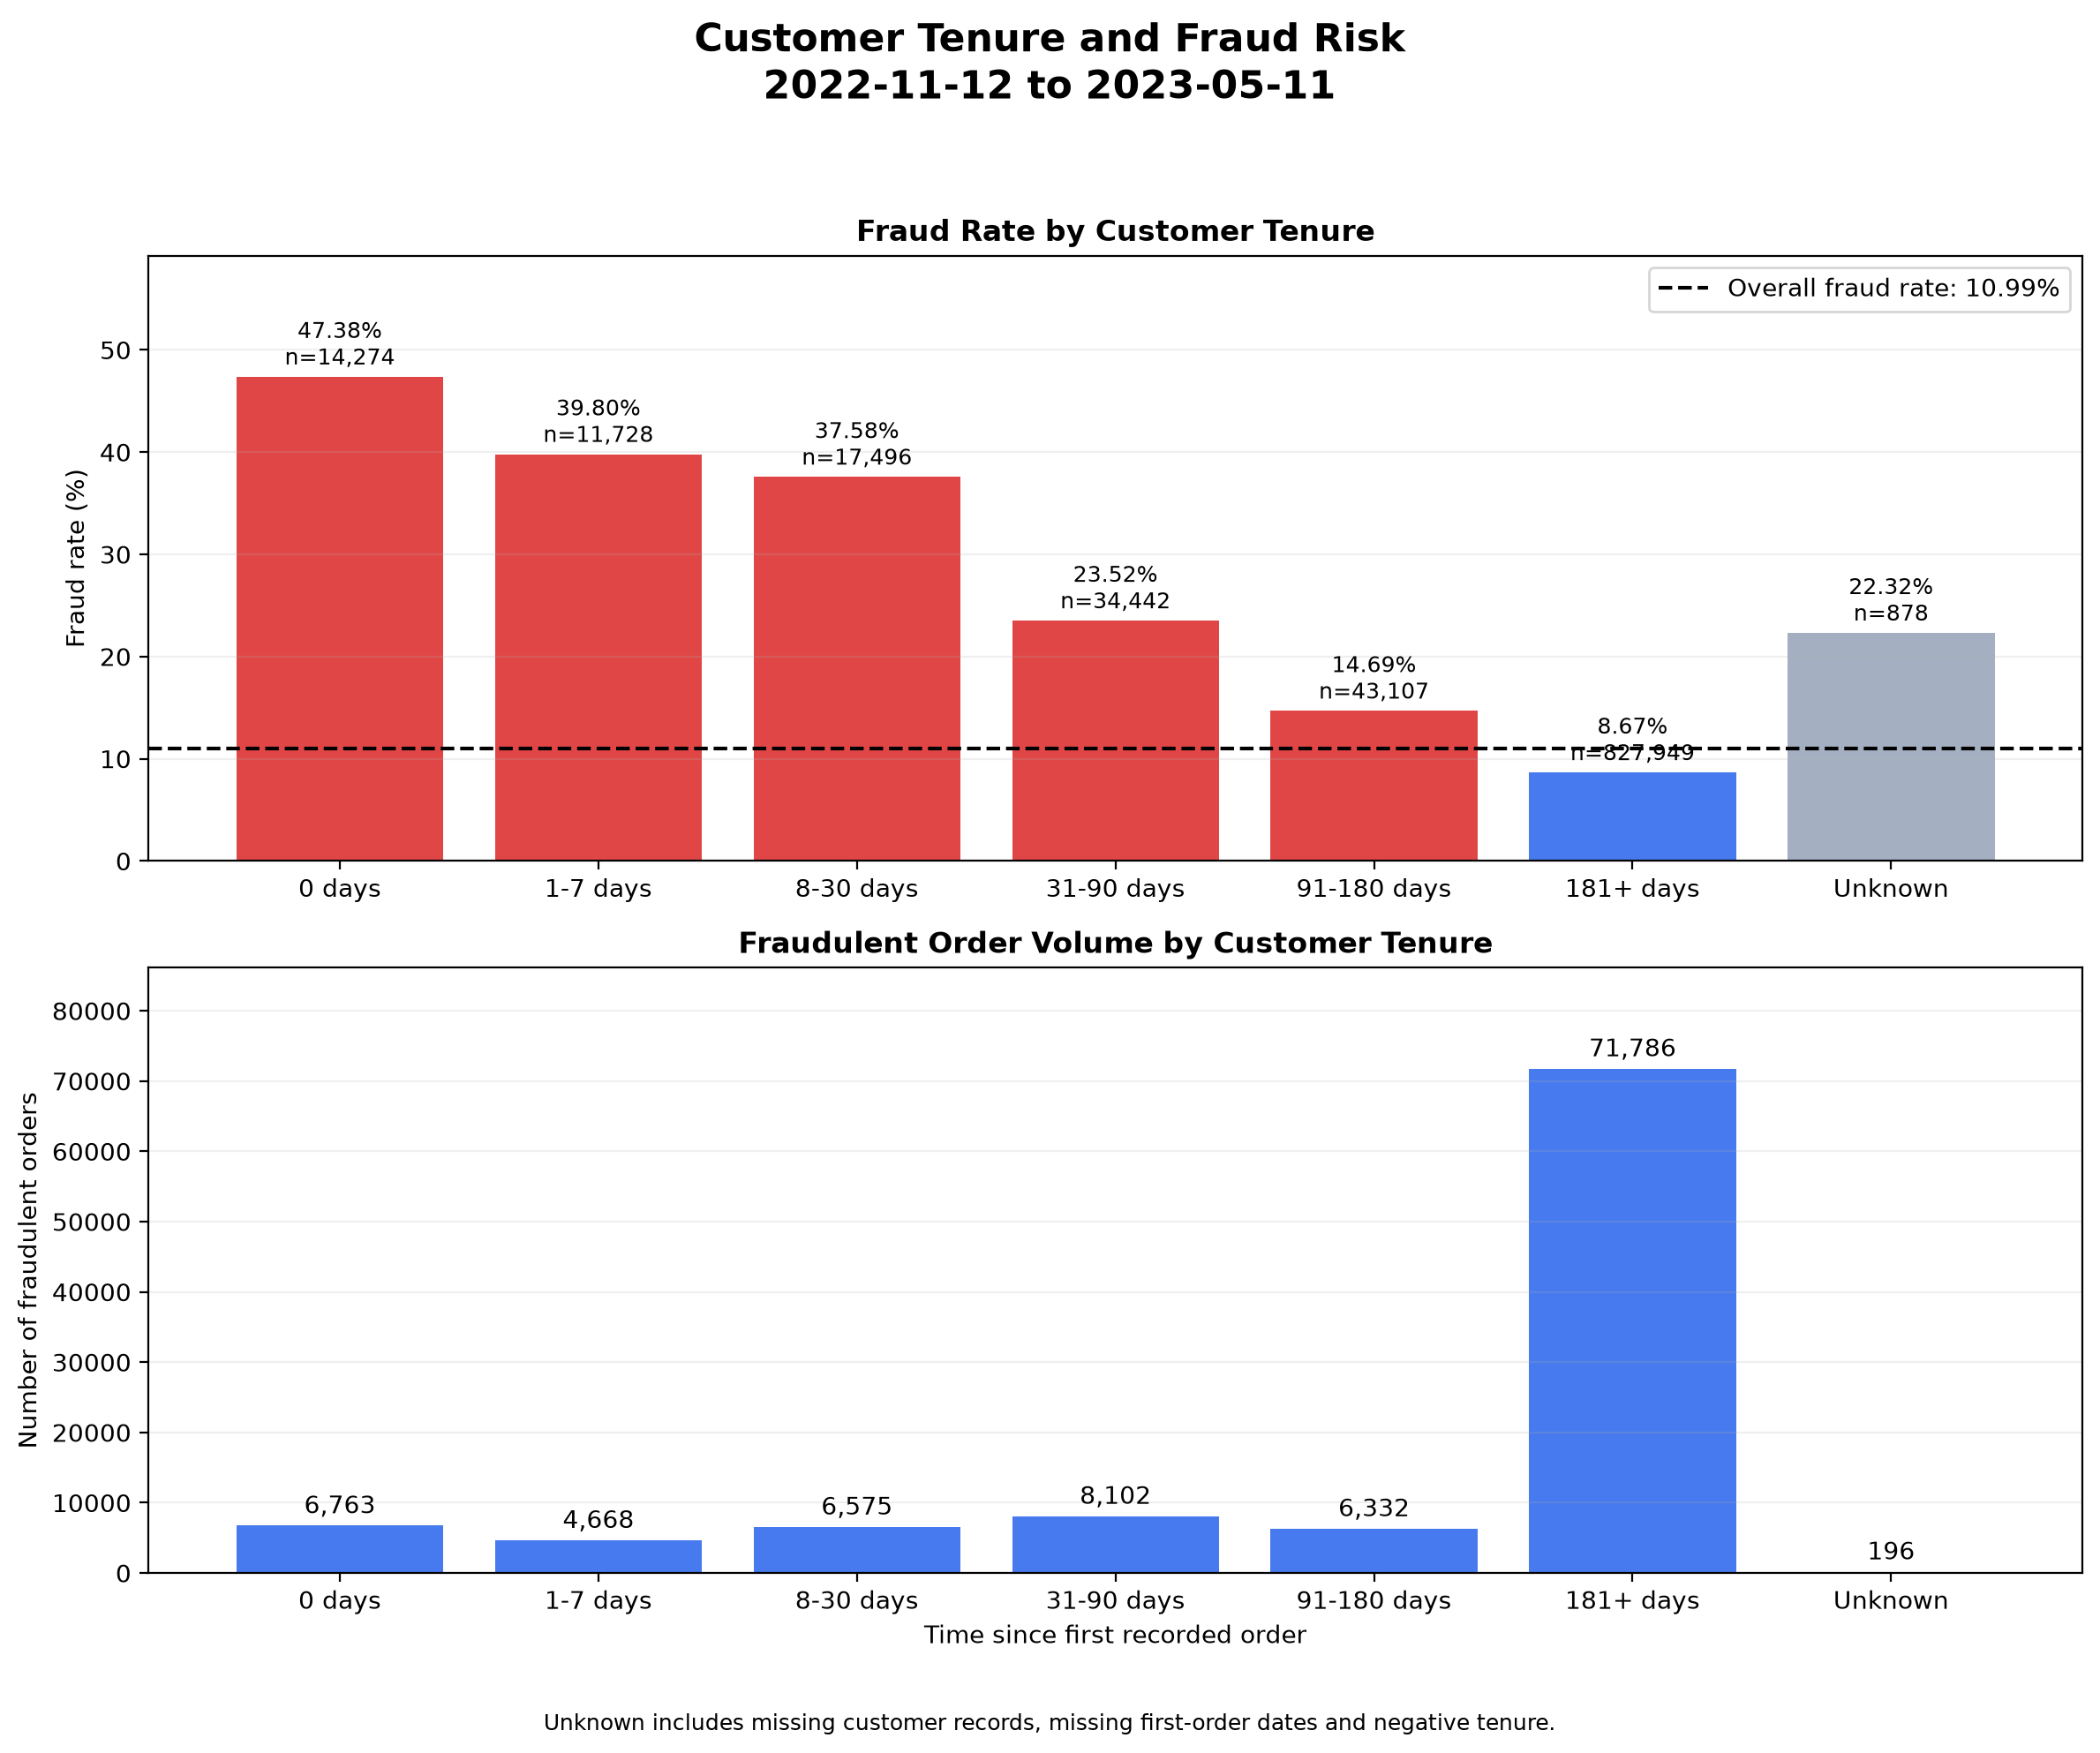

,tenure_group,fraud_orders,share_of_fraud_pct
0,0 days,6763.0,6.476605
1,1-7 days,4668.0,4.470322
2,8-30 days,6575.0,6.296566
3,31-90 days,8102.0,7.758901
4,91-180 days,6332.0,6.063856
5,181+ days,71786.0,68.746050
6,Unknown,196.0,0.187700


In [7]:
display(q2)
q2.to_csv(OUTPUT_DIR / "q2_customer_tenure_fraud.csv", index=False)
q2_chart = plot_tenure_fraud(q2, start_date, end_date, OUTPUT_DIR)
display(Image(filename=str(q2_chart), width=900))
if q2["fraud_orders"].sum() > 0:
    shares = q2[["tenure_group", "fraud_orders"]].copy()
    shares["share_of_fraud_pct"] = 100 * shares["fraud_orders"] / q2["fraud_orders"].sum()
    display(shares)

### 6.1 Historical findings and recommended action
In the original snapshot, fraud rates decreased from 47.38% on the first recorded order day to 39.80% (1–7 days), 37.58% (8–30 days), 23.52% (31–90 days), 14.69% (91–180 days) and 8.67% (181+ days). First-order-day risk was approximately 5.5 times that of the longest tenure group.

However, customers with 181+ days of purchasing history accounted for 71,786 fraudulent orders, approximately 68.7% of all fraud cases, because that group contained the largest transaction volume. The Unknown group contained 878 labelled orders and had a 22.32% fraud rate, so missing or inconsistent customer information should be investigated rather than ignored.

**Recommendation:** Consider proportionate additional verification for early purchasing activity while retaining monitoring of long-term accounts. Tenure alone should not determine an automatic rejection. Further analysis by country, payment method and other risk factors is needed before making causal claims. These are order-level rates, not the percentage of distinct customers who committed fraud.

## 7. Query 3 — Monthly financial exposure associated with fraud
**Business question:** How do the recorded order values associated with fraud change over time within each market?

The query separately sums non-negative recorded order and refund values for fraudulent orders, records missing/negative amounts, counts refunds exceeding order values, and calculates average valid fraudulent order value. Values are not added across markets because currency denomination has not been confirmed. A missing or invalid amount is excluded from the corresponding sum, not silently interpreted as zero. The first and last months may be incomplete.

In [8]:
show_sql(query_monthly_financial_exposure)

WITH monthly_summary AS (
    SELECT
        o.country_code,

        DATE_FORMAT(
            o.order_date, '%Y-%m'
        ) AS order_month,

        COUNT(*) AS total_orders,

        SUM(
            CASE WHEN l.is_fraud IN (0, 1)
                THEN 1 ELSE 0 END
        ) AS labelled_orders,

        SUM(
            CASE WHEN l.is_fraud = 1
                THEN 1 ELSE 0 END
        ) AS fraud_orders,

        SUM(
            CASE WHEN l.is_fraud = 0
                THEN 1 ELSE 0 END
        ) AS non_fraud_orders,

        SUM(
            CASE WHEN l.is_fraud IS NULL
                   OR l.is_fraud NOT IN (0, 1)
                THEN 1 ELSE 0 END
        ) AS unlabelled_orders,

        SUM(
            CASE
                WHEN l.is_fraud = 1
                 AND o.order_value >= 0
                THEN o.order_value
                ELSE NULL
            END
        ) AS fraud_order_value,

        SUM(
            CASE
                WHEN l.is_fraud = 1
                 AND o

,country_code,order_month,total_orders,labelled_orders,fraud_orders,non_fraud_orders,unlabelled_orders,fraud_order_value,fraud_refund_value,invalid_order_value_count,invalid_refund_value_count,refund_exceeds_order_count,fraud_rate_pct,avg_fraud_order_value
0,BD,2022-11,7103,7102.0,1043.0,6059.0,1.0,5685.458970,0.0,0.0,0.0,0.0,14.6860,5.4511
1,BD,2022-12,9985,9985.0,2691.0,7294.0,0.0,13099.644421,0.0,0.0,0.0,0.0,26.9504,4.8679
2,BD,2023-01,9598,9598.0,2823.0,6775.0,0.0,13386.501270,0.0,0.0,0.0,0.0,29.4124,4.7419
3,BD,2023-02,9582,9582.0,2749.0,6833.0,0.0,13469.740741,0.0,0.0,0.0,0.0,28.6892,4.8999
4,BD,2023-03,10415,10414.0,3270.0,7144.0,1.0,16609.885700,0.0,0.0,0.0,0.0,31.4000,5.0795
5,BD,2023-04,9245,9245.0,3256.0,5989.0,0.0,17142.148988,0.0,0.0,0.0,0.0,35.2190,5.2648
6,BD,2023-05,3632,3632.0,1601.0,2031.0,0.0,8592.805484,0.0,0.0,0.0,0.0,44.0804,5.3671
7,MY,2022-11,42857,42857.0,1687.0,41170.0,0.0,20991.946980,0.0,0.0,0.0,0.0,3.9364,12.4434
8,MY,2022-12,68952,68950.0,2634.0,66316.0,2.0,35253.595416,0.0,0.0,0.0,0.0,3.8202,13.3841
9,MY,2023-01,63437,63436.0,2268.0,61168.0,1.0,30764.811239,0.0,0.0,0.0,0.0,3.5753,13.5647


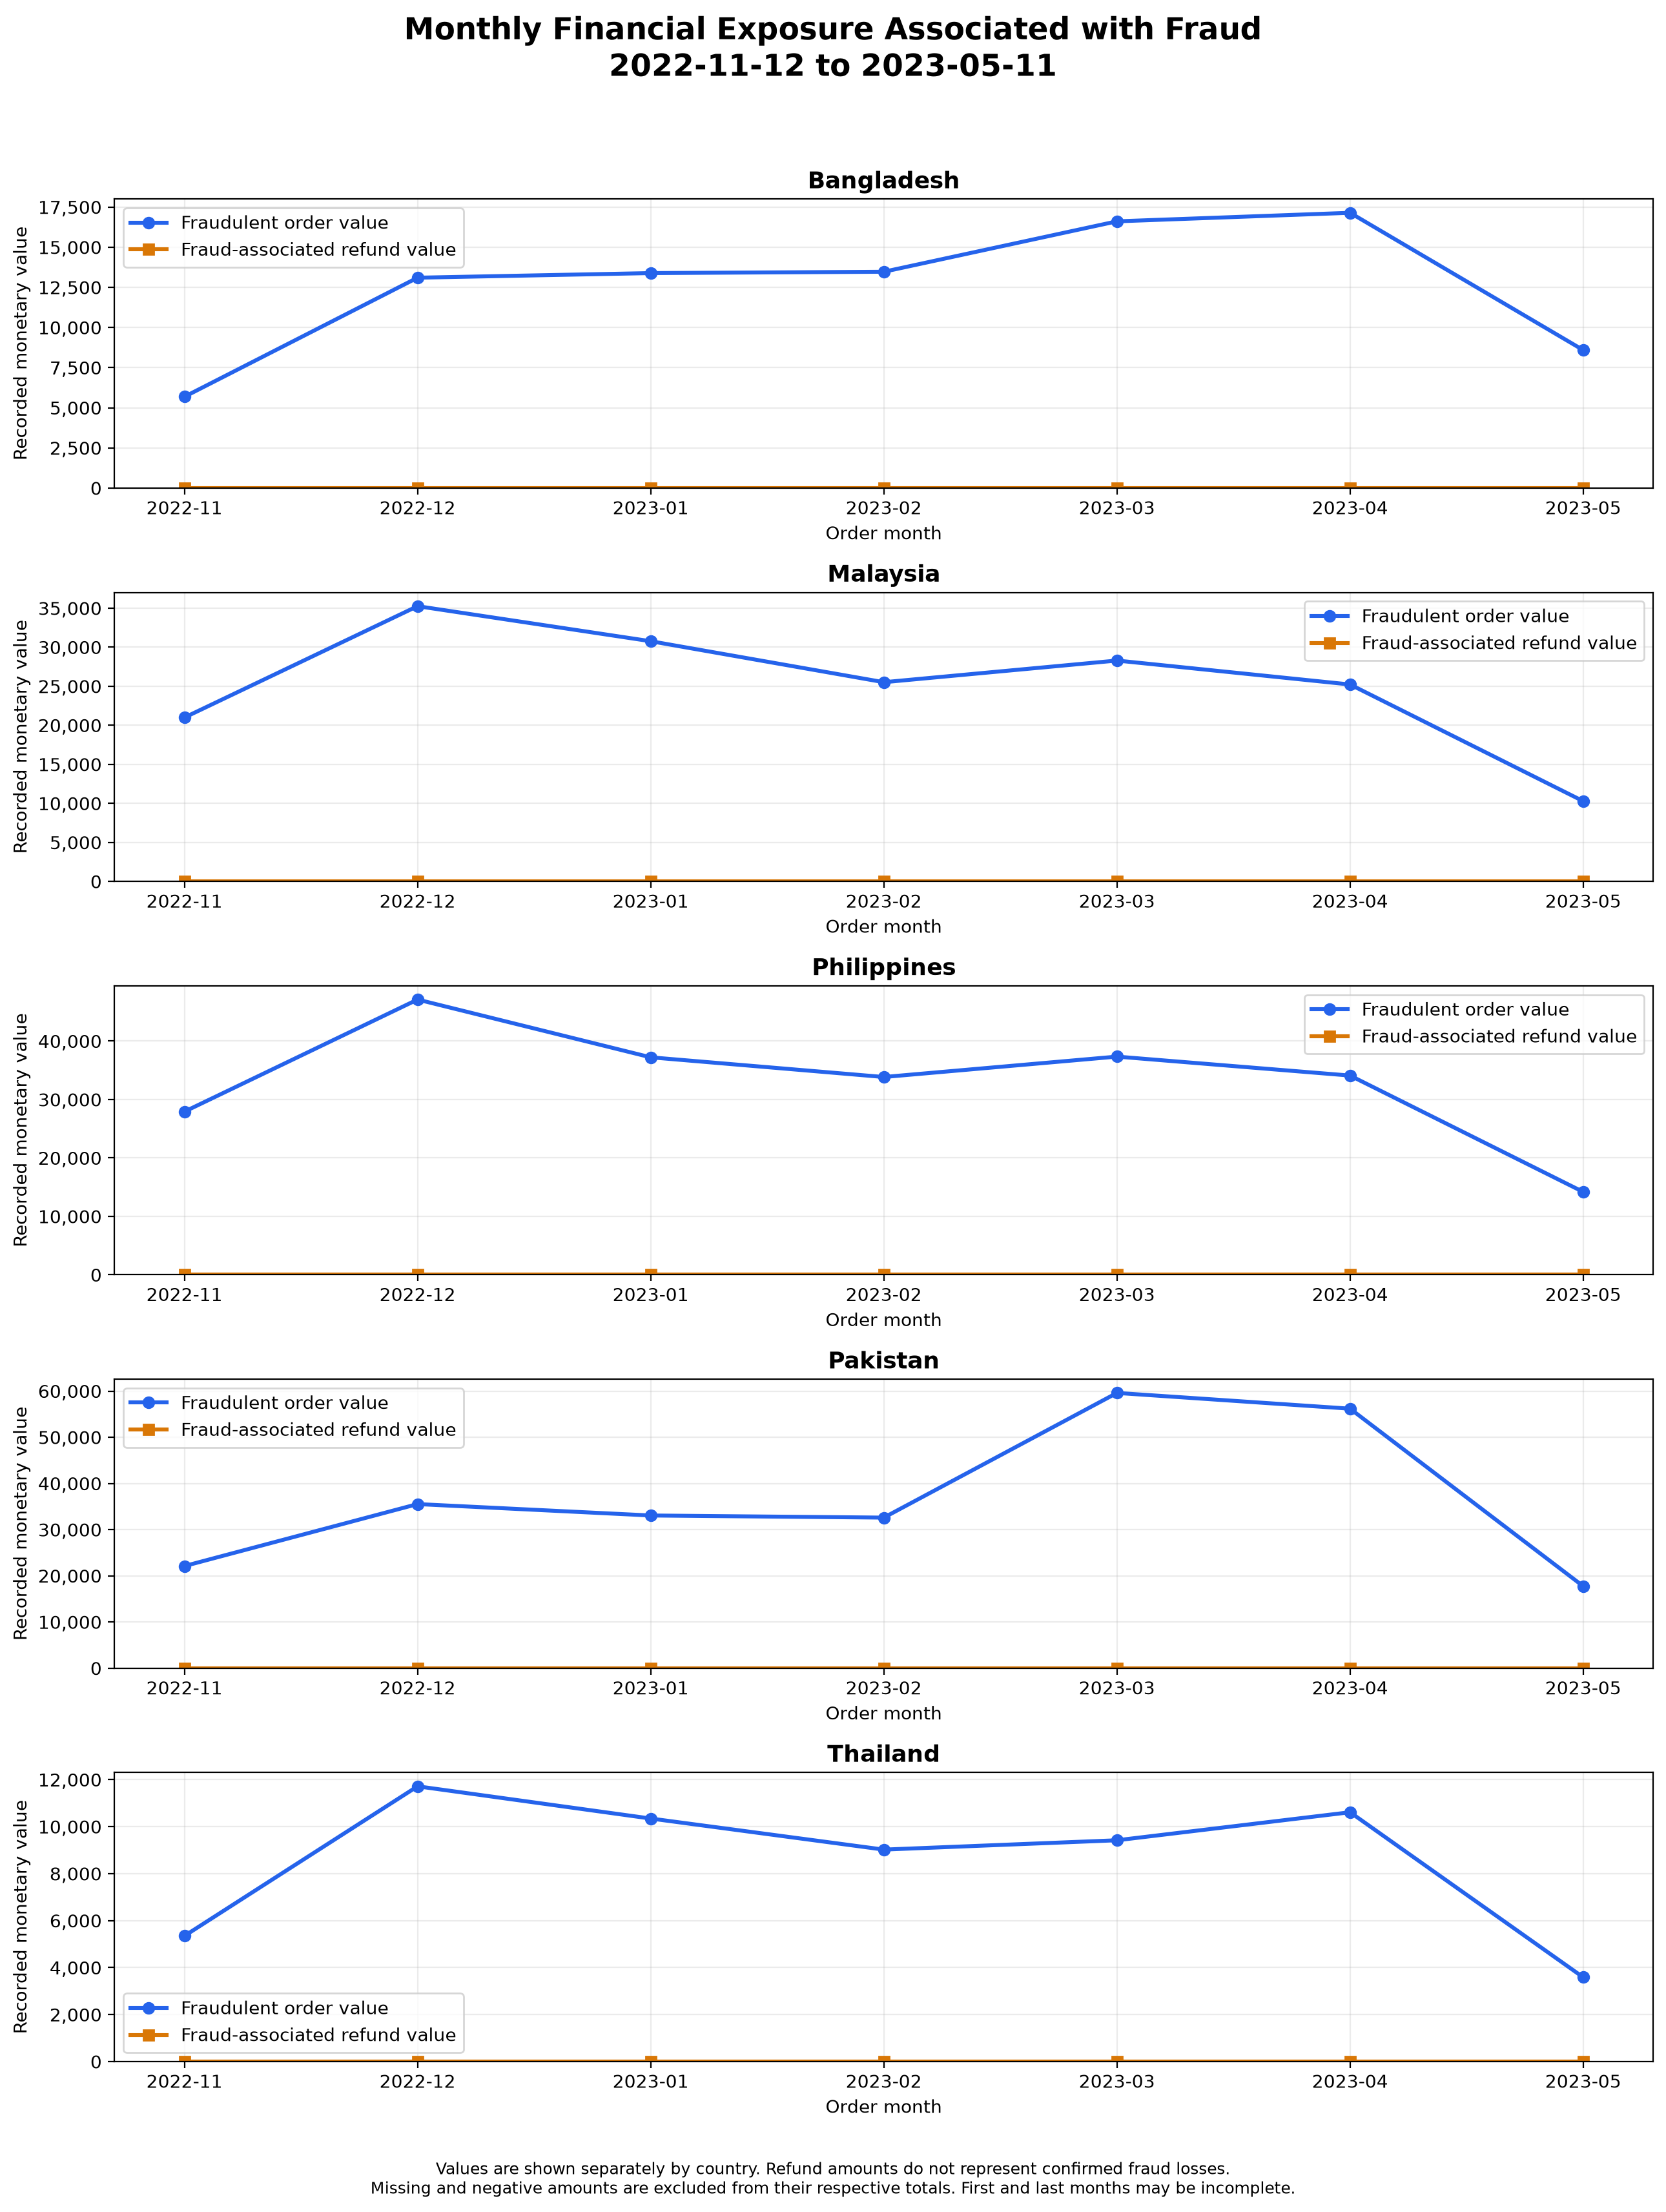

Peak recorded monthly fraudulent order value within each market:


,country_code,order_month,fraud_order_value,fraud_orders
5,BD,2023-04,17142.148988,3256.0
8,MY,2022-12,35253.595416,2634.0
15,PH,2022-12,47108.908891,5108.0
25,PK,2023-03,59593.691571,10566.0
29,TH,2022-12,11715.443899,648.0


Fraud-associated financial anomalies:


invalid_order_value_count     0.0
invalid_refund_value_count    0.0
refund_exceeds_order_count    0.0
dtype: float64

In [9]:
display(q3)
q3.to_csv(OUTPUT_DIR / "q3_monthly_financial_exposure.csv", index=False)
q3_chart = plot_financial_exposure(q3, start_date, end_date, OUTPUT_DIR)
display(Image(filename=str(q3_chart), width=900))
valid_amounts = q3.dropna(subset=["fraud_order_value"])
peaks = (valid_amounts.sort_values("fraud_order_value", ascending=False)
         .drop_duplicates("country_code").sort_values("country_code"))
print("Peak recorded monthly fraudulent order value within each market:")
display(peaks[["country_code", "order_month", "fraud_order_value", "fraud_orders"]])
print("Fraud-associated financial anomalies:")
display(q3[["invalid_order_value_count", "invalid_refund_value_count", "refund_exceeds_order_count"]].sum())

### 7.1 Historical findings and recommended action
The original snapshot showed these within-market peaks (recorded units, rounded to two decimal places):

| Country | Peak month | Fraudulent order value | Fraudulent orders |
|---|---|---:|---:|
| Bangladesh | April 2023 | 17,142.15 | 3,256 |
| Malaysia | December 2022 | 35,253.60 | 2,634 |
| Philippines | December 2022 | 47,108.91 | 5,108 |
| Pakistan | March 2023 | 59,593.69 | 10,566 |
| Thailand | December 2022 | 11,715.44 | 648 |

Pakistan's recorded fraudulent order value rose substantially between February and March 2023. Malaysia, the Philippines and Thailand had their respective peaks in December 2022. The lower May totals should not be interpreted as a reduction in risk because the available data ends on 11 May.

**Recommendation:** Investigate periods with higher fraud-associated transaction values within each market and compare them with transaction volumes and business events. The short observation period cannot establish recurring seasonality. Confirm currency denomination and the meaning of financial fields before estimating loss or comparing markets.

## 8. Supplementary data quality analysis — Refund values
The original chart showed a flat refund line at zero for all five markets. We therefore examined the refund distribution independently by fraud-label status, using the same composite join and date filter.

In [10]:
display(refund_audit)
refund_rates = refund_audit.copy()
refund_rates["positive_refund_pct"] = (100 * refund_rates["positive_refunds"] /
                                        refund_rates["total_orders"].where(refund_rates["total_orders"] > 0))
display(refund_rates[["fraud_status", "total_orders", "positive_refund_pct"]])
refund_audit.to_csv(OUTPUT_DIR / "refund_data_quality.csv", index=False)
print(f"Orders with recorded refunds exceeding order value: {int(refund_audit['refund_exceeds_order'].sum()):,}")

,fraud_status,total_orders,zero_refunds,positive_refunds,negative_refunds,missing_refunds,refund_exceeds_order
0,Non-fraud,845452,263512.0,581940.0,0.0,0.0,199684.0
1,Fraud,104422,104422.0,0.0,0.0,0.0,0.0
2,Unlabelled,15,8.0,7.0,0.0,0.0,2.0


,fraud_status,total_orders,positive_refund_pct
0,Non-fraud,845452,68.831820
1,Fraud,104422,0.000000
2,Unlabelled,15,46.666667


Orders with recorded refunds exceeding order value: 199,686


### 8.1 Interpretation of the refund anomaly
In the original diagnostic results, all 104,422 fraudulent orders had zero recorded refund values, whereas 581,940 of 845,452 non-fraudulent orders had positive recorded refunds. Across labelled and unlabelled orders, 199,686 records had refund amounts exceeding order value. No negative or missing refund values were reported in this snapshot.

The zero refund line therefore reflects the stored data, rather than an apparent chart-scaling or SQL aggregation error. It does **not** establish that fraud caused no financial loss. The refund field may describe a later transaction outcome, a label-dependent business process or a data quality issue; the precise explanation requires source-data documentation. Amounts above order value should be investigated, not assumed to be invalid without confirming field definitions.

The unusually strong association also reinforces the risk of target leakage if refund information becomes available only after the fraud prediction time. The group's shared modelling feature function excludes `refund_value`. This diagnostic does not prove the mechanism behind the association.

## 9. Performance and readiness for PBI 14
SQL aggregation returns compact result tables rather than transferring raw customer and order records. The same reusable functions can be orchestrated with Prefect, retrieving a single consistent snapshot and then generating reports after the transaction has closed. The timing below is for the SQL/validation stages plus the supplementary diagnostic; it is not a full end-to-end Prefect benchmark.

In [11]:
timings = pd.DataFrame([{"stage": name, "seconds": round(seconds, 2)}
                        for name, seconds in query_times.items()])
display(timings)
print(f"Combined business query time: {sum(query_times[k] for k in ('Query 1', 'Query 2', 'Query 3')):.2f}s")
print("Output files:")
for name in ["q1_payment_fraud.csv", "q1_payment_fraud_heatmap.png",
             "q2_customer_tenure_fraud.csv", "q2_customer_tenure_fraud.png",
             "q3_monthly_financial_exposure.csv", "q3_monthly_financial_exposure.png",
             "refund_data_quality.csv"]:
    path = OUTPUT_DIR / name
    assert path.is_file() and path.stat().st_size > 0, name
    print(name)
print("PASS: All expected analytical outputs exist.")

,stage,seconds
0,Query 1,7.69
1,Query 2,13.54
2,Query 3,7.92
3,Refund diagnostic,6.98


Combined business query time: 29.15s
Output files:
q1_payment_fraud.csv
q1_payment_fraud_heatmap.png
q2_customer_tenure_fraud.csv
q2_customer_tenure_fraud.png
q3_monthly_financial_exposure.csv
q3_monthly_financial_exposure.png
refund_data_quality.csv
PASS: All expected analytical outputs exist.


## 10. Conclusion and limitations
The three analyses provide complementary perspectives on fraud risk: payment-method exposure, purchasing history and recorded monetary exposure. Historical evidence suggests prioritising high-risk payment combinations and early-life customer screening, while continuing to monitor established customers who account for most observed fraud cases. Monthly trends can guide investigation planning within markets.

Limitations include incomplete labels, missing or negative customer tenure, unconfirmed monetary units and refund definitions, partial months, and potential confounding. These descriptive findings do not establish causation or prove future risk. The notebook refreshes live results; the narrative uses 27 nov 2026 snapshot and should be updated if subsequent results change materially.